# 04 · Shortcut check: what are the detectors really recognising?

Very high detection scores can come from **shortcuts**, i.e. surface clues such as layout or
odd characters, instead of writing style. This notebook:

1. shows which clues TF-IDF relies on and how formatting differs between human and AI text
   (from `src/shortcut_features.py`);
2. compares every detector trained and tested on the **original** text with the same detector
   trained and tested on **normalised** text (`src/normalize_text.py`: no line breaks, no invisible
   characters, look-alike letters mapped back). Results for normalised text are in `results/normalized/`.

A large drop after normalisation means part of the original score came from formatting shortcuts.
On the attacked sets, normalisation also acts as a simple defence.

In [4]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir()) / "src"))
from report_utils import *

ROOT = project_root()
RES, NORM = ROOT / "results", ROOT / "results" / "normalized"
FIG, TAB = output_dirs(ROOT)
set_style()

orig, lrs_o = load_results(RES)
norm, lrs_n = load_results(NORM)
keys = [k for k in ["baseline", "tfidf_word", "tfidf_word_char", "roberta-base", "Qwen2.5-0.5B"]
        if k in set(orig["model"]) and k in set(norm["model"])]
print("Detectors with both versions:", [DETECTOR_NAMES[k] for k in keys])

Detectors with both versions: ['Baseline', 'TF-IDF (word)', 'TF-IDF (word+char)', 'RoBERTa']


## 1. Formatting differences between human and AI text (training set)

In [5]:
fmt = pd.read_csv(TAB / "formatting_by_source_original.csv", index_col=0)
fmt.insert(0, "type", ["human" if s == "human" else GENERATOR_TYPE.get(s, "") for s in fmt.index])
fmt = fmt.sort_values(["type", "has_line_break"], ascending=[False, False])
fmt.columns = ["Type", "Has line break (%)", "Line breaks / 100 words", "Has blank line (%)",
               "Has list lines (%)", "Has non-ASCII (%)", "Mean words"]
save_table(fmt, "formatting_by_source", TAB, "Formatting of training texts by source (no augmentation)")
fmt

saved tables/formatting_by_source.csv and .tex


,Type,Has line break (%),Line breaks / 100 words,Has blank line (%),Has list lines (%),Has non-ASCII (%),Mean words
source,,,,,,,
human,human,61.1,3.83,0.0,1.2,30.2,293.0
cohere-chat,chat,81.0,5.57,75.3,12.5,18.6,185.0
mistral-chat,chat,80.5,5.86,79.3,14.5,16.1,201.0
chatgpt,chat,70.5,4.91,70.1,13.5,16.4,263.0
gpt3,base,99.9,11.34,99.9,13.0,12.5,132.0
mistral,base,89.5,8.54,81.1,11.5,20.2,297.0
cohere,base,78.8,6.13,74.7,9.0,17.7,228.0
gpt2,base,78.1,11.29,76.1,2.4,19.2,327.0


## 2. The clues TF-IDF relies on most

In [6]:
top_o = pd.read_csv(TAB / "tfidf_top_features_original.csv")
ai_ = top_o[top_o["direction"] == "AI"].head(15).reset_index(drop=True)
hu_ = top_o[top_o["direction"] == "human"].head(15).reset_index(drop=True)
side = pd.DataFrame({"Towards AI": ai_["feature"], "Weight (AI)": ai_["weight"],
                     "Towards human": hu_["feature"], "Weight (human)": hu_["weight"]})
side.index = range(1, len(side) + 1)
side = side.rename_axis("Rank")
save_table(side, "tfidf_top_features", TAB, "Strongest TF-IDF (word+char) clues, original text")
side

saved tables/tfidf_top_features.csv and .tex


,Towards AI,Weight (AI),Towards human,Weight (human)
Rank,,,,
1,char: ' > ',9.832,word: in,-5.739
2,char: ' a ',5.863,word: and,-5.717
3,char: '## ',5.318,word: br,-5.644
4,char: ' ##',5.318,word: at,-5.606
5,word: instructions,5.205,char: 'ly ',-5.204
6,word: ingredients,5.047,word: to,-4.879
7,word: and the,4.912,word: of,-4.858
8,char: 's: ',4.608,word: an,-4.162
9,word: that the,4.406,word: all,-4.102


## 3. Original vs normalised text (TPR at 5% FPR, no augmentation)

In [7]:
def tpr_by_condition(df, key):
    d = df[(df["model"] == key) & (df["aug"] == 0) & (df["attack"] == "all")]
    return d.groupby("condition")["tpr_at_5fpr"].mean() * 100

conds = ["test_seen", "test_unseen", "test_reppen", "test_seen_attacks"]
rows = []
for key in keys:
    o, n = tpr_by_condition(orig, key), tpr_by_condition(norm, key)
    for c in conds:
        rows.append({"Detector": DETECTOR_NAMES[key], "Condition": CONDITION_NAMES[c],
                     "Original": o.get(c, np.nan), "Normalised": n.get(c, np.nan)})
cmp_ = pd.DataFrame(rows)
cmp_["Change (pp)"] = cmp_["Normalised"] - cmp_["Original"]
cmp_ = cmp_.round(1).set_index(["Detector", "Condition"])
save_table(cmp_, "normalisation_effect", TAB,
           "TPR (%) at 5% FPR before and after removing formatting clues (no augmentation)")
cmp_

saved tables/normalisation_effect.csv and .tex


Original  Normalised  Change (pp)
Detector           Condition                                       
Baseline           Seen gen.          33.3        33.7          0.4
                   Held-out gen.      22.1        22.3          0.1
                   Rep. penalty        2.3         2.3         -0.0
                   Seen attacks       33.6        34.0          0.4
TF-IDF (word)      Seen gen.          78.5        78.6          0.1
                   Held-out gen.      83.6        83.3         -0.3
                   Rep. penalty       43.9        43.7         -0.2
                   Seen attacks       75.3        75.4          0.1
TF-IDF (word+char) Seen gen.          82.1        80.9         -1.2
                   Held-out gen.      85.1        84.0         -1.1
                   Rep. penalty       49.6        47.1         -2.4
                   Seen attacks       79.2        77.9         -1.3
RoBERTa            Seen gen.          99.5        96.2         -3.3
                   Held-out gen.      98.0        97.6         -0.3
                   Rep. penalty       90.5        77.9        -12.6
                   Seen attacks       96.2        92.6         -3.6

saved figures/normalisation_effect.pdf and .png


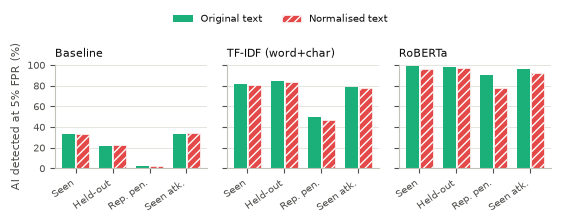

In [8]:
dets = [DETECTOR_NAMES[k] for k in keys if k != "tfidf_word"]
x = np.arange(len(conds))
fig, axes = plt.subplots(1, len(dets), figsize=(min(PAGE_W, 1.75 * len(dets) + 0.4), 2.2),
                         sharey=True, squeeze=False)
for ax, det in zip(axes[0], dets):
    d = cmp_.loc[det].reindex([CONDITION_NAMES[c] for c in conds])
    ax.bar(x - 0.19, d["Original"], 0.36, color=PAIR[0], label="Original text")
    ax.bar(x + 0.19, d["Normalised"], 0.36, color=PAIR[1], hatch="////", edgecolor="#fcfcfb",
           linewidth=0.5, label="Normalised text")
    ax.set_title(det, loc="left", color=INK)
    ax.set_xticks(x, ["Seen", "Held-out", "Rep. pen.", "Seen atk."], rotation=35, ha="right")
    ax.set_ylim(0, 100)
    ax.grid(axis="x", visible=False)
axes[0][0].set_ylabel("AI detected at 5% FPR (%)")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0, 1, 0.86))
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
save_fig(fig, "normalisation_effect", FIG)
plt.show()

## 4. Normalisation as a defence against held-out attacks
False-positive rate on attacked **human** texts (lower is better; target 5%).

In [9]:
def fpr_by_attack(df, key):
    d = df[(df["model"] == key) & (df["aug"] == 0) & (df["condition"] == "test_heldout_attacks")
           & (df["attack"] != "all")]
    return d.groupby("attack")[["tpr_at_5fpr", "fpr_observed"]].mean() * 100

rows = []
for key in [k for k in keys if k not in ("baseline", "tfidf_word")]:
    o, n = fpr_by_attack(orig, key), fpr_by_attack(norm, key)
    for a in HELDOUT_ATTACKS:
        rows.append({"Detector": DETECTOR_NAMES[key], "Attack": a.replace("_", " "),
                     "FPR original": o.loc[a, "fpr_observed"], "FPR normalised": n.loc[a, "fpr_observed"],
                     "TPR original": o.loc[a, "tpr_at_5fpr"], "TPR normalised": n.loc[a, "tpr_at_5fpr"]})
defence = pd.DataFrame(rows).round(1).set_index(["Detector", "Attack"])
save_table(defence, "normalisation_defence", TAB,
           "Held-out attacks before and after normalisation: FPR on attacked human texts and TPR (%)")
defence

saved tables/normalisation_defence.csv and .tex


FPR original  FPR normalised  \
Detector           Attack                                            
TF-IDF (word+char) homoglyph                  74.8             4.6   
                   zero width space          100.0             4.6   
                   whitespace                  5.1             4.6   
                   upper lower                 5.1             4.6   
                   insert paragraphs           5.1             4.6   
RoBERTa            homoglyph                  10.0             4.7   
                   zero width space           89.2             4.7   
                   whitespace                  1.2             4.7   
                   upper lower                 1.5             0.7   
                   insert paragraphs          97.1             4.7   

                                      TPR original  TPR normalised  
Detector           Attack                                           
TF-IDF (word+char) homoglyph                  96.5            80.9  
                   zero width space          100.0            80.9  
                   whitespace                 82.1            80.9  
                   upper lower                82.1            80.9  
                   insert paragraphs          82.1            80.9  
RoBERTa            homoglyph                  82.3            96.2  
                   zero width space           94.9            96.2  
                   whitespace                 98.8            96.2  
                   upper lower                99.0            89.4  
                   insert paragraphs          99.9            96.2

saved figures/normalisation_defence.pdf and .png


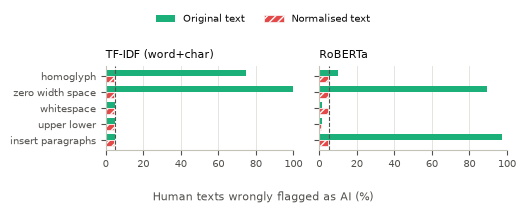

In [10]:
dd = [DETECTOR_NAMES[k] for k in keys if k not in ("baseline", "tfidf_word")]
atks = [a.replace("_", " ") for a in HELDOUT_ATTACKS]
y = np.arange(len(atks))[::-1]
fig, axes = plt.subplots(1, len(dd), figsize=(min(PAGE_W, 2.2 * len(dd) + 0.9), 2.0),
                         sharey=True, squeeze=False)
for ax, det in zip(axes[0], dd):
    d = defence.loc[det].reindex(atks)
    ax.barh(y + 0.19, d["FPR original"], 0.36, color=PAIR[0], label="Original text")
    ax.barh(y - 0.19, d["FPR normalised"], 0.36, color=PAIR[1], hatch="////",
            edgecolor="#fcfcfb", linewidth=0.5, label="Normalised text")
    ax.axvline(5, color=INK2, linewidth=0.8, linestyle="--")
    ax.set_title(det, loc="left", color=INK)
    ax.set_xlim(0, 100)
    ax.grid(axis="y", visible=False)
axes[0][0].set_yticks(y, atks)
fig.supxlabel("Human texts wrongly flagged as AI (%)", fontsize=8, color=INK2)
handles, labels = axes[0][0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0, 1, 0.84))
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
save_fig(fig, "normalisation_defence", FIG)
plt.show()

## 5. What to conclude
* **Large drops in section 3** → part of the original score came from formatting shortcuts.
* **Small changes in section 3** → the detectors mostly rely on writing style, not layout.
* **Lower FPR in section 4** → normalisation is a cheap, effective defence against these attacks;
  it costs nothing to train and needs no attacked training data (compare with augmentation).